# Actividad 2 · Modelo de referencia y evaluación confiable

En esta actividad vamos a comparar dos formas de clasificar solicitudes de soporte. Al final elegirás una, explicarás por qué la elegiste y comprobarás que puedes guardar el modelo y volver a usarlo.

- **Valor:** 8% de la materia.
- **Asignación:** Lunes 5 de octubre de 2026.
- **Entrega:** Domingo 11 de octubre de 2026, a las 23:59, hora de Monterrey.

## ¿Qué vamos a resolver?

Imagina que un servicio de soporte recibe mensajes en español y necesita enviarlos al área adecuada: **acceso, pagos, conectividad o software**. Tu modelo sugerirá una de esas categorías. No hará cambios en cuentas ni realizará cobros.

Usaremos dos modelos que vimos en Clase 4: **regresión logística** y **Multinomial Naive Bayes**. Ambos aprenderán de los mismos ejemplos. La idea es hacer una comparación justa y dejar claro cómo llegaste a tu recomendación.

## ¿Qué puedes consultar?

Esta actividad se resuelve con lo trabajado en **Clases 1–4**. Puedes abrir sus notebooks, revisar los ejemplos y adaptarlos. No necesitas memorizar las funciones ni usar temas de Clases 5–6.

De las primeras clases retomamos el **corpus**, es decir, nuestra colección de textos, y las **etiquetas**, que indican la categoría de cada ejemplo. De Clase 3 usaremos **TF-IDF**, una forma de representar cada texto con números a partir de sus términos. De Clase 4 retomamos los clasificadores, su evaluación y la forma de guardarlos con `skops`.

Un **Pipeline** reúne la transformación del texto y el clasificador en un mismo objeto. Así, al recibir un mensaje nuevo, aplica los mismos pasos que aprendió durante el entrenamiento.

## Elige los datos y prepara la comparación

La opción que ya viene preparada es `data/corpus_actividad_02_v2.csv`. Son ejemplos ficticios diferentes de los usados en las demostraciones de clase. Conserva el reparto que trae el archivo y usa **solo `text_processed` como texto de entrada**.

También puedes usar el corpus de tu Actividad 1. En ese caso, explica de dónde viene, cómo lo preparaste y cómo separaste los datos. Debe tener al menos dos categorías en entrenamiento, y debes justificar que hay ejemplos suficientes y adecuados de tus categorías en validación y prueba. Ajusta la carga y `LABELS`, la lista de categorías, a tu propio corpus. No necesitas que tenga el mismo número de filas ni las mismas categorías que el corpus proporcionado. Si no puedes comprobar estas condiciones a tiempo, usa el archivo de esta actividad.

Antes de entrenar, deja por escrito:

1. Las dos alternativas: **TF-IDF + regresión logística** y **TF-IDF + Multinomial Naive Bayes**.
2. La configuración de cada una. Puedes conservar los valores de Clase 4; no se pide probar muchas combinaciones de parámetros.
3. La métrica principal con la que vas a comparar y la regla que usarás si hay empate.

Trabajaremos con tres **particiones**, es decir, tres grupos de datos con funciones distintas:

- **`train` — entrenamiento:** ejemplos de los que aprende el modelo.
- **`validation` — validación:** ejemplos que usamos para comparar las alternativas y elegir una.
- **`test` — prueba:** ejemplos que reservamos para evaluar el modelo después de elegirlo.

Los dos modelos deben usar exactamente los mismos datos en cada etapa. No uses `test` para decidir cuál gana. Una pequeña ventaja en este corpus no demuestra que un modelo sea mejor en cualquier situación.

## Antes de empezar

Usaremos Python con NumPy, pandas, scikit-learn, matplotlib y skops. NumPy ayuda con los cálculos; pandas organiza los datos en tablas; scikit-learn transforma textos, entrena y evalúa; matplotlib dibuja la matriz de confusión; skops guarda y recupera el modelo completo. No necesitas GPU ni descargar modelos ya entrenados.

### Colab

1. Abre este notebook y sube `corpus_actividad_02_v2.csv` al panel **Archivos**. Espera a que termine la carga.
2. Sube también `verificar_recarga.py`: lo usaremos en el paso 6.
3. Ejecuta las celdas de arriba hacia abajo. La primera celda de código instala únicamente las bibliotecas que faltan y muestra las versiones disponibles.
4. Si se instaló una biblioteca y después falla su importación, reinicia la sesión y vuelve a ejecutar desde el principio.

Al terminar, descarga el notebook y los archivos de `entrega/`. Guardar el notebook en Drive no guarda automáticamente los CSV ni el modelo que generaste durante la sesión.

In [1]:
from pathlib import Path
import sys, subprocess, importlib.util, json, platform, hashlib, re, unicodedata
from importlib.metadata import version
necesarios = {"numpy":"numpy==2.2.6", "pandas":"pandas==2.2.3",
              "sklearn":"scikit-learn==1.6.1", "skops":"skops==0.11.0",
              "matplotlib":"matplotlib==3.10.3"}
faltan = [paquete for modulo,paquete in necesarios.items()
          if importlib.util.find_spec(modulo) is None]
if faltan:
    subprocess.run([sys.executable,"-m","pip","install",*faltan],check=True)
import numpy as np
import pandas as pd
import sklearn
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
import skops.io as sio
import matplotlib.pyplot as plt
versiones = {p:version(p) for p in necesarios.values() for p in [p.split("==")[0]]}
versiones["python"] = platform.python_version()
print(versiones)
completados = set()

{'numpy': '2.4.4', 'pandas': '3.0.5', 'scikit-learn': '1.8.0', 'skops': '0.16.0', 'matplotlib': '3.11.1', 'python': '3.14.4'}


## Conoce el archivo de datos

Antes de entrenar, revisemos qué significa cada columna. También puedes consultar `data/README.md`.

| Columna | Qué significa |
|---|---|
| `id` | Identificador de una fila; permite volver al ejemplo que quieres revisar. |
| `family` | Grupo de mensajes que son variantes de una misma solicitud. |
| `split` | Indica si la fila pertenece a `train`, `validation` o `test`. |
| `label` | Categoría de referencia con la que compararemos la predicción. |
| `text_original` | Texto antes de la preparación. |
| `text_processed` | Texto preparado que recibirá el modelo. |

Por ejemplo, dos maneras de escribir la misma solicitud pueden pertenecer a una misma familia. Deben quedarse en el mismo grupo de datos para evitar que el modelo se evalúe con una variante de algo que ya vio al entrenar.

`text_processed` conserva acentos y negaciones. Se aplicó **normalización NFC**, que unifica formas de representar caracteres como las letras acentuadas, y se redujeron los espacios sobrantes. Esto prepara el texto, pero no garantiza que el clasificador entienda una negación.

En el corpus proporcionado hay **40 familias, tres variantes por familia y cuatro categorías**. Por cada categoría, seis familias se usan para entrenamiento, dos para validación y dos para prueba. Los mensajes son ficticios, no contienen datos de personas reales y están autorizados para uso educativo.

Las categorías son: **acceso**, para problemas de cuenta o autenticación; **pagos**, para cargos y documentos de pago; **conectividad**, para red e internet; y **software**, para aplicaciones y archivos. Si un mensaje menciona un problema ya resuelto y otro que continúa, la etiqueta corresponde al que sigue pendiente.

El modelo recibe únicamente `text_processed`. No agregues `id`, `family`, `split` ni `label` al texto: son datos para organizar y evaluar el experimento. Conserva las familias y particiones originales. No muevas ejemplos entre grupos para mejorar la puntuación.

Este corpus ya está preparado para que te concentres en la comparación de modelos. Sus ejemplos cortos y repetitivos no cubren toda la variedad del lenguaje real. Si usas tu corpus de Actividad 1, conserva y explica tus propias decisiones de preparación.

La siguiente celda busca el CSV, lo carga en la tabla `df` y crea la carpeta `entrega/`, donde guardarás tus resultados. Si no encuentra el archivo, revisa que hayas terminado de subirlo a Colab o que hayas extraído la carpeta `data/` junto al notebook.

In [2]:
nombre = "corpus_actividad_02_v2.csv"
bases = [Path.cwd(), *Path.cwd().parents]
candidatos = [Path.cwd()/nombre]
for base in bases:
    candidatos += [base/"data"/nombre, base/"data"/nombre,
                   base/"data"/nombre]
ARCHIVO = next((p for p in candidatos if p.is_file()),None)
if ARCHIVO is None:
    raise FileNotFoundError("Extrae data/ junto al notebook o termina de subir el CSV al panel Archivos de Colab.")
df = pd.read_csv(ARCHIVO,keep_default_na=False,encoding="utf-8")
OUT = Path.cwd()/"entrega"
OUT.mkdir(exist_ok=True)
print("Fuente localizada:",ARCHIVO.name)

Fuente localizada: corpus_actividad_02_v2.csv


## 1. Revisa los datos antes de entrenar

Primero explica qué texto va a recibir tu modelo, qué categoría devolverá y para qué servirá esa respuesta. Después revisa la tabla:

1. Comprueba las columnas, los valores que faltan, los identificadores y cuántos ejemplos hay de cada categoría.
2. Revisa que cada familia aparezca en una sola partición. Haz lo mismo con los textos procesados que sean idénticos.
3. Comprueba que todas las categorías presentes en validación y prueba también estén en entrenamiento.
4. Anota el tamaño de cada grupo y explica si su distribución permite hacer la comparación. Conserva la tabla con `id`, `family`, `split` y `label`.

Estos controles ayudan a evitar una **fuga de información**: que el entrenamiento o la elección del modelo aprovechen datos que deberían estar reservados para otra etapa. Por ejemplo, repartir variantes de una misma solicitud entre entrenamiento y prueba puede hacer que el resultado parezca mejor de lo que realmente es.

No cambies las particiones después de ver los resultados. Recuerda que el texto de entrada es solo `text_processed`.

**Apoyo:** Clase 4, sección 1, función `comprobar_particiones`.

In [3]:
LABELS = ["acceso", "pagos", "conectividad", "software"]
PARTICIONES = ["train", "validation", "test"]

def comprobar_particiones(tabla):
    problemas = []
    faltan = {"id", "family", "split", "label", "text_processed"} - set(tabla.columns)
    if faltan:
        problemas.append(f"faltan columnas: {sorted(faltan)}")
        return problemas
    if tabla.isna().any().any() or (tabla == "").any().any():
        problemas.append("hay valores faltantes")
    if tabla["id"].duplicated().any():
        problemas.append("ids repetidos")
    familias = tabla.groupby("family")["split"].nunique()
    if (familias > 1).any():
        problemas.append(f"familias en mas de una particion: {sorted(familias[familias > 1].index)}")
    textos = tabla.groupby("text_processed")["split"].nunique()
    if (textos > 1).any():
        problemas.append(f"textos identicos en varias particiones: {int((textos > 1).sum())}")
    en_train = set(tabla.loc[tabla["split"] == "train", "label"])
    for p in ["validation", "test"]:
        extra = set(tabla.loc[tabla["split"] == p, "label"]) - en_train
        if extra:
            problemas.append(f"categorias de {p} que no estan en train: {sorted(extra)}")
    return problemas

print("columnas:", list(df.columns))
print("filas:", len(df), "| valores faltantes:", int((df == "").sum().sum()), "| ids repetidos:", int(df["id"].duplicated().sum()))
print("particiones que existen:", sorted(df["split"].unique()))
print("categorias que existen:", sorted(df["label"].unique()))
print()
print(pd.crosstab(df["split"], df["label"]).loc[PARTICIONES, LABELS])
print()
print("familias por particion:", df.groupby("split")["family"].nunique().loc[PARTICIONES].to_dict())
print("variantes por familia:", df.groupby("family").size().value_counts().to_dict())
print("textos procesados repetidos:", int(df["text_processed"].duplicated().sum()))
print("problemas encontrados:", comprobar_particiones(df))

tabla_particiones = df[["id", "family", "split", "label"]].copy()
completados.add(1)

columnas: ['id', 'family', 'split', 'label', 'text_original', 'text_processed']


filas: 120 | valores faltantes: 0 | ids repetidos: 0
particiones que existen: ['test', 'train', 'validation']
categorias que existen: ['acceso', 'conectividad', 'pagos', 'software']



label       acceso  pagos  conectividad  software
split                                            
train           18     18            18        18
validation       6      6             6         6
test             6      6             6         6

familias por particion: {'train': 24, 'validation': 8, 'test': 8}
variantes por familia: {3: 40}
textos procesados repetidos: 0
problemas encontrados: []


### Explica lo que encontraste

Cuenta qué encontraste al revisar los datos: tamaños de los grupos, categorías y comprobaciones de familias y textos repetidos. Explica por qué tu separación permite seguir con el experimento.

Escribe con tus palabras y apóyate en lo que muestra tu ejecución.

Respuesta:

El modelo solo lee `text_processed` y devuelve una de cuatro categorías: acceso, pagos, conectividad o software. Sirve para enrutar el mensaje al área correcta.

120 filas, 6 columnas, sin nulos ni IDs repetidos. 40 familias de 3 variantes: 72 en train, 24 en validation, 24 en test, parejo por categoría (18/6/6). Ninguna familia se repite entre particiones y las categorías de validation/test también están en train. Puedo seguir: no hay fuga. Lo único flojo es que validation y test son chicos.

## 2. Compara los modelos y elige con validación

Ahora construye un Pipeline para cada alternativa. Crea un vectorizador y un clasificador nuevos para cada uno; no compartas un objeto que ya se haya entrenado.

1. Entrena ambos usando únicamente `train`.
2. Evalúalos sobre los mismos ejemplos de `validation`.
3. Registra las métricas por categoría y el **F1 macro**: el promedio del F1 de las categorías, dando el mismo peso a cada una. F1 combina precisión y recall; repasaremos qué significa cada medida en el paso 3.
4. Aplica la métrica principal y la regla de desempate que declaraste antes de entrenar.

En tu explicación, relaciona el código con estas dos acciones: **`fit` aprende** a partir de los datos de entrenamiento; **`predict` usa lo aprendido** para asignar una categoría a textos nuevos.

Comprueba también que el vocabulario y los pesos IDF se aprendieron solo con `train`. El **vocabulario** es la lista de términos que reconoce el vectorizador; **IDF**, frecuencia inversa de documento, da más peso a términos que aparecen en menos documentos del conjunto usado para aprender. Puedes comparar esos valores con los de otro vectorizador ajustado solo con `train`, o hacer una comprobación equivalente.

Busca un término que aparezca únicamente en validación y demuestra que no entró al vocabulario. Si no hay ninguno, agrega una palabra inventada a una copia de un texto de validación solo para esta comprobación; no cambies los datos originales.

Guarda la elección en `decision.json`: nombre del modelo, regla de selección, semilla e IDs de validación. La **semilla** es un número que ayuda a repetir las operaciones que usan azar. La ruta más sencilla es conservar el modelo ya entrenado con `train`, sin volver a ajustarlo con `train + validation`.

**Apoyo:** Clase 3, sección 3; Clase 4, funciones `construir` y `medir`.

### Mi plan antes de entrenar

- Alternativas: TF-IDF con regresión logística y TF-IDF con Multinomial Naive Bayes.
- Configuración: TF-IDF con minúsculas, palabras sueltas y pares de palabras (1 y 2), sin quitar nada. Regresión logística con C = 1.0 y máximo 1000 iteraciones. Naive Bayes con alpha = 1.0. Usé valores sencillos y no probé otras combinaciones.
- Métrica principal: F1 macro en validation.
- Si empatan: gana la que tenga más accuracy en validation. Si siguen empatadas, gana Naive Bayes por ser más simple.
- Semilla: 42.

In [4]:
SEMILLA = 42
CONFIG = {
    "tfidf": {"lowercase": True, "ngram_range": [1, 2], "min_df": 1},
    "regresion_logistica": {"C": 1.0, "max_iter": 1000, "random_state": SEMILLA},
    "naive_bayes": {"alpha": 1.0},
}
METRICA = "F1 macro en validation"
DESEMPATE = "si empatan en F1 macro, gana la de mayor accuracy en validation; si siguen empatadas, Naive Bayes (la mas simple)"
print("Metrica principal:", METRICA)
print("Desempate:", DESEMPATE)
print("Semilla:", SEMILLA)
print("Configuracion:", json.dumps(CONFIG))

Metrica principal: F1 macro en validation
Desempate: si empatan en F1 macro, gana la de mayor accuracy en validation; si siguen empatadas, Naive Bayes (la mas simple)
Semilla: 42
Configuracion: {"tfidf": {"lowercase": true, "ngram_range": [1, 2], "min_df": 1}, "regresion_logistica": {"C": 1.0, "max_iter": 1000, "random_state": 42}, "naive_bayes": {"alpha": 1.0}}


In [5]:
def construir(nombre):
    vec = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=1)
    if nombre == "tfidf_regresion_logistica":
        clf = LogisticRegression(C=1.0, max_iter=1000, random_state=SEMILLA)
    elif nombre == "tfidf_naive_bayes":
        clf = MultinomialNB(alpha=1.0)
    else:
        raise ValueError(nombre)
    return Pipeline([("tfidf", vec), ("clf", clf)])

train = df[df["split"] == "train"]
valid = df[df["split"] == "validation"]
X_train, y_train = train["text_processed"], train["label"]
X_valid, y_valid = valid["text_processed"], valid["label"]

modelos = {}
resultados_valid = {}
for nombre in ["tfidf_regresion_logistica", "tfidf_naive_bayes"]:
    pipe = construir(nombre)
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_valid)
    informe = classification_report(y_valid, pred, labels=LABELS, output_dict=True, zero_division=0)
    modelos[nombre] = pipe
    resultados_valid[nombre] = {
        "f1_macro": f1_score(y_valid, pred, labels=LABELS, average="macro"),
        "accuracy": accuracy_score(y_valid, pred),
        "por_categoria": {c: informe[c] for c in LABELS},
    }
    print(nombre)
    print(classification_report(y_valid, pred, labels=LABELS, zero_division=0, digits=3))

tabla = pd.DataFrame({n: {"F1 macro": v["f1_macro"], "accuracy": v["accuracy"]} for n, v in resultados_valid.items()}).T
print(tabla.round(4))

a, b = resultados_valid["tfidf_regresion_logistica"], resultados_valid["tfidf_naive_bayes"]
if abs(a["f1_macro"] - b["f1_macro"]) > 1e-12:
    elegido = max(resultados_valid, key=lambda n: resultados_valid[n]["f1_macro"])
    regla_usada = "mayor F1 macro en validation"
elif abs(a["accuracy"] - b["accuracy"]) > 1e-12:
    elegido = max(resultados_valid, key=lambda n: resultados_valid[n]["accuracy"])
    regla_usada = "empate en F1 macro; gano mayor accuracy en validation"
else:
    elegido = "tfidf_naive_bayes"
    regla_usada = "empate total; gano la mas simple"
print("\nElegido:", elegido, "|", regla_usada)

tfidf_regresion_logistica
              precision    recall  f1-score   support

      acceso      0.667     1.000     0.800         6
       pagos      1.000     0.500     0.667         6
conectividad      0.667     1.000     0.800         6
    software      1.000     0.500     0.667         6

    accuracy                          0.750        24
   macro avg      0.833     0.750     0.733        24
weighted avg      0.833     0.750     0.733        24

tfidf_naive_bayes
              precision    recall  f1-score   support

      acceso      0.667     1.000     0.800         6
       pagos      1.000     0.500     0.667         6
conectividad      0.667     1.000     0.800         6
    software      1.000     0.500     0.667         6

    accuracy                          0.750        24
   macro avg      0.833     0.750     0.733        24
weighted avg      0.833     0.750     0.733        24

                           F1 macro  accuracy
tfidf_regresion_logistica    0.7333     

Los dos modelos dieron exactamente los mismos números en validation (F1 macro 0.7333 y accuracy 0.75), y además predicen igual en los 24 ejemplos. Por eso la regla de desempate llegó hasta el final y ganó Naive Bayes.

In [6]:
pipe_elegido = modelos[elegido]
vec = pipe_elegido.named_steps["tfidf"]

solo_train = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=1).fit(X_train)
con_valid = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=1).fit(pd.concat([X_train, X_valid]))
print("vocabulario igual al de un vectorizador ajustado solo con train:", vec.vocabulary_ == solo_train.vocabulary_)
print("IDF igual:", bool(np.allclose(vec.idf_, solo_train.idf_)))
print("tamano del vocabulario con train:", len(vec.vocabulary_), "| si hubiera visto tambien validation:", len(con_valid.vocabulary_))

analizador = solo_train.build_analyzer()
terminos_valid = {t for texto in X_valid for t in analizador(texto)}
solo_en_valid = sorted(terminos_valid - set(vec.vocabulary_))
print("terminos que solo aparecen en validation:", len(solo_en_valid))
if solo_en_valid:
    ejemplo = solo_en_valid[0]
    print("ejemplo:", repr(ejemplo), "| esta en el vocabulario del modelo:", ejemplo in vec.vocabulary_)
else:
    ejemplo = None
    copia = X_valid.iloc[0] + " zxqvtk"
    print("no hay ninguno; uso una palabra inventada en una copia:", repr(copia))
    print("zxqvtk en el vocabulario:", "zxqvtk" in vec.vocabulary_)

decision = {
    "modelo": elegido,
    "regla_de_seleccion": f"{METRICA}; desempate: {DESEMPATE}",
    "regla_aplicada": regla_usada,
    "semilla": SEMILLA,
    "ids_validacion": valid["id"].tolist(),
}
(OUT / "decision.json").write_text(json.dumps(decision, ensure_ascii=False, indent=2), encoding="utf-8")
print("decision.json guardado antes de tocar test; ids de validacion:", len(decision["ids_validacion"]))
completados.add(2)

vocabulario igual al de un vectorizador ajustado solo con train: True
IDF igual: True
tamano del vocabulario con train: 377 | si hubiera visto tambien validation: 477
terminos que solo aparecen en validation: 100
ejemplo: 'abre' | esta en el vocabulario del modelo: False
decision.json guardado antes de tocar test; ids de validacion: 24


### Explica lo que encontraste

Compara tus resultados de validación y explica qué modelo elegiste con la regla que habías definido. Describe también cómo comprobaste que el vocabulario y los IDF se aprendieron solo con entrenamiento.

Escribe con tus palabras y apóyate en lo que muestra tu ejecución.

Respuesta:

Entrené ambos con `fit` usando solo train (ahí el vectorizador arma el vocabulario y los pesos, y el clasificador aprende). Con `predict` los probé en validation.

Empataron en todo (F1 macro 0.7333, accuracy 0.75), así que gané por mi regla de desempate: Naive Bayes. Con solo 24 ejemplos tampoco se puede concluir mucho más.

Comparé el vectorizador del pipeline contra uno ajustado solo con train: vocabulario e IDF iguales (377 términos). Si hubiera visto también validation serían 477, hay 100 que solo salen ahí, por ejemplo "abre".

Guardé la decisión en `decision.json` antes de tocar test.

## 3. Evalúa el modelo elegido con prueba

Ya elegiste un modelo. Ahora usa `test` para conocer su resultado final. Mantén esa decisión: no evalúes las dos alternativas en prueba para cambiar de ganador ni ajustes las reglas después de ver el resultado.

Guarda las predicciones con su ID, texto, etiqueta de referencia y etiqueta predicha. Calcula estas medidas:

- **Accuracy o exactitud:** proporción de mensajes clasificados correctamente.
- **Precision o precisión de una categoría:** de los mensajes que el modelo asignó a esa categoría, cuántos realmente pertenecían a ella.
- **Recall o exhaustividad:** de los mensajes que realmente pertenecían a una categoría, cuántos encontró el modelo.
- **F1 por categoría:** combina precisión y recall en una sola medida.
- **Support o cantidad de ejemplos:** cuántos mensajes de referencia hay de cada categoría.
- **F1 macro:** promedio de los F1 de las categorías.

Dibuja la **matriz de confusión**, una tabla que cruza la categoría real con la predicha. Pon las categorías reales en las filas y las predichas en las columnas, y muestra su orden. Elige una categoría y comprueba a mano su precisión y recall: divide sus aciertos entre el total de su columna para precisión y entre el total de su fila para recall. Si un denominador es cero, explica el tratamiento que usaste y comprueba que coincide con la biblioteca.

No se pide alcanzar una puntuación mínima. Se evalúa que el procedimiento y la interpretación sean correctos.

**Apoyo:** ejemplo numérico y matriz del laboratorio de Clase 4.

              precision    recall  f1-score   support

      acceso      0.375     0.500     0.429         6
       pagos      0.750     0.500     0.600         6
conectividad      1.000     1.000     1.000         6
    software      0.500     0.500     0.500         6

    accuracy                          0.625        24
   macro avg      0.656     0.625     0.632        24
weighted avg      0.656     0.625     0.632        24

accuracy: 0.6250 | F1 macro: 0.6321

matriz de confusion (filas = real, columnas = predicha), orden: ['acceso', 'pagos', 'conectividad', 'software']
                   pred acceso  pred pagos  pred conectividad  pred software
real acceso                  3           0                  0              3
real pagos                   3           3                  0              0
real conectividad            0           0                  6              0
real software                2           1                  0              3


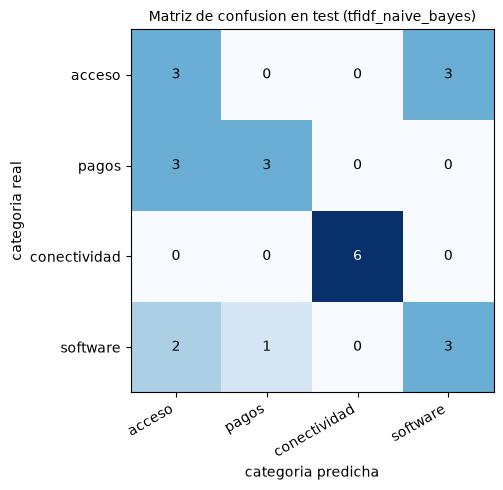

In [7]:
test = df[df["split"] == "test"].copy()
test["prediction"] = pipe_elegido.predict(test["text_processed"])

pred_test = test["prediction"]
y_test = test["label"]
informe_test = classification_report(y_test, pred_test, labels=LABELS, output_dict=True, zero_division=0)
print(classification_report(y_test, pred_test, labels=LABELS, digits=3, zero_division=0))
acc_test = accuracy_score(y_test, pred_test)
f1_macro_test = f1_score(y_test, pred_test, labels=LABELS, average="macro")
print(f"accuracy: {acc_test:.4f} | F1 macro: {f1_macro_test:.4f}")

cm = confusion_matrix(y_test, pred_test, labels=LABELS)
print("\nmatriz de confusion (filas = real, columnas = predicha), orden:", LABELS)
print(pd.DataFrame(cm, index=[f"real {c}" for c in LABELS], columns=[f"pred {c}" for c in LABELS]))

fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(LABELS))); ax.set_xticklabels(LABELS, rotation=30, ha="right")
ax.set_yticks(range(len(LABELS))); ax.set_yticklabels(LABELS)
ax.set_xlabel("categoria predicha"); ax.set_ylabel("categoria real")
ax.set_title(f"Matriz de confusion en test ({elegido})", fontsize=10)
for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout()
plt.savefig(OUT / "confusion.png", dpi=150)
plt.show()

In [8]:
categoria = "pagos"
k = LABELS.index(categoria)
aciertos = cm[k, k]
total_columna = cm[:, k].sum()
total_fila = cm[k, :].sum()
precision_mano = aciertos / total_columna if total_columna else 0.0
recall_mano = aciertos / total_fila if total_fila else 0.0
print(f"{categoria}: aciertos = {aciertos}, total de la columna = {total_columna}, total de la fila = {total_fila}")
print(f"precision a mano = {aciertos}/{total_columna} = {precision_mano:.4f}")
print(f"recall a mano    = {aciertos}/{total_fila} = {recall_mano:.4f}")
print("sklearn:", round(informe_test[categoria]["precision"], 4), round(informe_test[categoria]["recall"], 4))
assert abs(precision_mano - informe_test[categoria]["precision"]) < 1e-12
assert abs(recall_mano - informe_test[categoria]["recall"]) < 1e-12
print("denominadores en cero:", int((cm.sum(axis=0) == 0).sum() + (cm.sum(axis=1) == 0).sum()))
completados.add(3)

pagos: aciertos = 3, total de la columna = 4, total de la fila = 6
precision a mano = 3/4 = 0.7500
recall a mano    = 3/6 = 0.5000
sklearn: 0.75 0.5
denominadores en cero: 0


### Explica lo que encontraste

Explica qué dicen las métricas y la matriz sobre tu modelo. Incluye la cuenta de precisión y recall de la categoría que revisaste a mano, usando tus propios resultados.

Escribe con tus palabras y apóyate en lo que muestra tu ejecución.

Respuesta:

En test: accuracy 0.625, F1 macro 0.632. Conectividad salió perfecta (1.0 y 1.0). Las demás más flojas: acceso F1 0.429, pagos 0.6, software 0.5. 6 ejemplos por categoría.

En la matriz se ve que acceso se confunde con software (3), pagos con acceso (3) y software se va a acceso (2) o pagos (1).

Revisé pagos a mano: 3 aciertos de 4 predichos (precisión 0.75) y de 6 reales (recall 0.5). Cuadra con lo que da la librería.

## 4. Revisa los errores y explica los límites

Mira hasta tres errores reales de tu modelo. Para cada uno, muestra el ID, el texto, la categoría de referencia y la predicción. Explica qué pudo causar el error y qué información te falta para confirmarlo. Una explicación posible es una hipótesis, no una causa demostrada.

Si encuentras menos de tres errores, analiza los que haya y completa la exploración con ejemplos propios, separados de los datos de prueba. Si no hay errores, dilo. No inventes fallos ni sumes tus ejemplos nuevos a las métricas de `test`.

Incluye al menos un caso con **negación**, como una frase que contenga “no”, o con **OOV** (*out of vocabulary*), es decir, palabras que no están en el vocabulario aprendido. Propón una mejora para un experimento futuro, sin aplicarla para cambiar el resultado final de esta actividad.

Por último, comprueba tu control de familias: en una copia de los datos, coloca ejemplos de una misma familia en particiones distintas y demuestra que tu revisión detecta el problema. No entrenes con esa copia. Explica por qué usar un Pipeline no corrige por sí solo una separación incorrecta de los datos.

**Apoyo:** prueba de contaminación de Clase 2, OOV de Clase 3 y análisis de errores de Clase 4.

In [9]:
errores = test[test["prediction"] != test["label"]][["id", "family", "text_processed", "label", "prediction"]]
print("errores en test:", len(errores), "de", len(test))
print("familias con errores:", errores.groupby("family").size().to_dict())
for _, fila in errores.drop_duplicates("family").head(3).iterrows():
    print(fila["id"], f"(familia {fila['family']})", "| real:", fila["label"], "| predicho:", fila["prediction"])
    print("   ", fila["text_processed"])
    fuera = [t for t in vec.build_analyzer()(fila["text_processed"]) if " " not in t and t not in vec.vocabulary_]
    print("    palabras que el modelo no conoce:", fuera)
errores.to_csv(OUT / "errores.csv", index=False, encoding="utf-8")

validacion_igual = (modelos["tfidf_regresion_logistica"].predict(X_valid) == modelos["tfidf_naive_bayes"].predict(X_valid)).all()
print("\nlos dos modelos predicen igual en todos los ejemplos de validation:", bool(validacion_igual))

print("\n--- ejemplos propios (no son de test y no entran a las metricas) ---")
propios = [
    "No puedo entrar a mi cuenta.",
    "El pago ya se resolvio, pero el programa no abre.",
    "No tengo internet en la oficina.",
    "Mi factura tiene un zxqvtk raro.",
]
analizador = vec.build_analyzer()
for texto in propios:
    fuera = [t for t in analizador(texto) if t not in vec.vocabulary_]
    print(repr(texto), "->", pipe_elegido.predict([texto])[0], "| terminos fuera del vocabulario:", fuera)

print("\n--- control de familias en una copia ---")
copia = df.copy()
fila = copia[(copia["split"] == "train") & (copia["family"] == "H001")].index[0]
mover = copia.loc[fila].copy()
mover["id"] = "COPIA-001"
mover["split"] = "test"
copia = pd.concat([copia, mover.to_frame().T], ignore_index=True)
print("problemas que detecta la revision en la copia:")
for p in comprobar_particiones(copia):
    print(" -", p)
print("problemas en los datos originales:", comprobar_particiones(df))
completados.add(4)

errores en test: 9 de 24
familias con errores: {'H009': 3, 'H020': 3, 'H039': 3}
A2-025 (familia H009) | real: acceso | predicho: software
    Mi identidad no se valida al intentar acceder al portal.
    palabras que el modelo no conoce: ['identidad', 'valida', 'intentar', 'acceder', 'portal']
A2-058 (familia H020) | real: pagos | predicho: acceso
    Puedo entrar a mi cuenta; el problema es un cobro que no reconozco.
    palabras que el modelo no conoce: ['cobro', 'reconozco']
A2-115 (familia H039) | real: software | predicho: acceso
    Las fórmulas de la hoja de cálculo dejaron de actualizarse.
    palabras que el modelo no conoce: ['fórmulas', 'hoja', 'cálculo', 'dejaron', 'actualizarse']

los dos modelos predicen igual en todos los ejemplos de validation: True

--- ejemplos propios (no son de test y no entran a las metricas) ---
'No puedo entrar a mi cuenta.' -> acceso | terminos fuera del vocabulario: ['puedo entrar', 'entrar mi']
'El pago ya se resolvio, pero el programa no abre

### Explica lo que encontraste

Describe los errores o casos exploratorios que revisaste. Distingue lo que observaste de lo que supones, y explica qué pasó al introducir el cruce de familia en una copia.

Escribe con tus palabras y apóyate en lo que muestra tu ejecución.

Respuesta:

9 errores de 24, todos de 3 familias (H009, H020, H039) con 3 cada una, porque las variantes de una familia son casi el mismo mensaje y fallan juntas.

- A2-025 (H009): "Mi identidad no se valida al intentar acceder al portal." Real acceso, predijo software. No conocía 5 palabras clave. Hipótesis: faltó vocabulario de acceso en train.
- A2-058 (H020): "Puedo entrar a mi cuenta; el problema es un cobro que no reconozco." Real pagos, predijo acceso. No conocía "cobro" ni "reconozco", y se fue por "entrar"/"cuenta". El modelo cuenta palabras, no entiende que "puedo entrar" descarta el problema de acceso.
- A2-115 (H039): "Las fórmulas de la hoja de cálculo dejaron de actualizarse." Real software, predijo acceso. Tampoco conocía casi ninguna palabra.

Con ejemplos propios (fuera de test): negación y vocabulario nuevo le cuestan. "El pago ya se resolvió, pero el programa no abre" lo mandó a pagos por la palabra "pago", sin notar que ya estaba resuelto. Una palabra inventada simplemente se ignora.

Mejora futura, sin aplicarla aquí: más ejemplos de train con vocabulario variado, casos "resuelto" vs "pendiente", y probar n-gramas de caracteres.

Control de familias: metí a propósito una variante de H001 en test en una copia y la revisión sí avisó "familias en más de una partición". En los datos originales no avisa nada. El Pipeline no lo detecta solo porque no sabe qué mensajes son de la misma familia.

## 5. Guarda el modelo y sus resultados

Vamos a guardar lo necesario para que otra persona pueda revisar tu trabajo y para que tú puedas volver a usar el modelo.

Guarda el Pipeline completo en `baseline.skops`. Debe incluir el vectorizador y el clasificador: guardar solo el clasificador dejaría fuera la forma de convertir el texto en números.

En la carpeta `entrega/`, guarda también `metricas.json`, `predicciones.csv`, `particiones.csv`, `confusion.png` y `manifiesto.json`. Conserva el `decision.json` del paso 2. La lista de entrega al final explica para qué sirve cada archivo.

El **manifiesto** es una ficha del experimento: debe indicar la fuente de datos, las versiones utilizadas, la semilla, la configuración, el orden de las categorías y el modelo elegido. Tus explicaciones van en el notebook; no se pide otro informe.

Antes de recuperar el modelo, usa `get_untrusted_types` para revisar si el archivo contiene tipos que `skops` no reconoce como confiables. Si aparecen, revisa su origen antes de cargarlos; no copies automáticamente la lista al argumento `trusted`. Los componentes estándar del ejemplo de Clase 4 no requieren añadir tipos a esa lista.

**Apoyo:** Clase 4, sección 4, guardado del Pipeline.

In [10]:
sio.dump(pipe_elegido, OUT / "baseline.skops")
tipos = sio.get_untrusted_types(file=OUT / "baseline.skops")
print("tipos no confiables:", tipos)
recuperado = sio.load(OUT / "baseline.skops", trusted=tipos if not tipos else [])
print("pasos del pipeline guardado:", [n for n, _ in recuperado.steps])

predicciones = test[["id", "text_processed", "label", "prediction"]]
predicciones.to_csv(OUT / "predicciones.csv", index=False, encoding="utf-8")
tabla_particiones.to_csv(OUT / "particiones.csv", index=False, encoding="utf-8")

metricas = {
    "modelo": elegido,
    "particion": "test",
    "accuracy": acc_test,
    "f1_macro": f1_macro_test,
    "por_categoria": {c: {"precision": informe_test[c]["precision"], "recall": informe_test[c]["recall"],
                          "f1": informe_test[c]["f1-score"], "support": int(informe_test[c]["support"])} for c in LABELS},
    "orden_categorias": LABELS,
    "matriz_confusion_filas_real_columnas_predicha": cm.tolist(),
    "validacion": {n: {"f1_macro": v["f1_macro"], "accuracy": v["accuracy"]} for n, v in resultados_valid.items()},
}
(OUT / "metricas.json").write_text(json.dumps(metricas, ensure_ascii=False, indent=2), encoding="utf-8")

manifiesto = {
    "fuente": ARCHIVO.name,
    "sha256_fuente": hashlib.sha256(ARCHIVO.read_bytes()).hexdigest(),
    "filas": len(df),
    "versiones": versiones,
    "semilla": SEMILLA,
    "configuracion": CONFIG,
    "orden_categorias": LABELS,
    "metrica_principal": METRICA,
    "desempate": DESEMPATE,
    "modelo_elegido": elegido,
    "texto_de_entrada": "solo text_processed",
}
(OUT / "manifiesto.json").write_text(json.dumps(manifiesto, ensure_ascii=False, indent=2), encoding="utf-8")
print("archivos en entrega/:", sorted(p.name for p in OUT.iterdir()))
completados.add(5)

tipos no confiables: []
pasos del pipeline guardado: ['tfidf', 'clf']
archivos en entrega/: ['baseline.skops', 'confusion.png', 'decision.json', 'errores.csv', 'manifiesto.json', 'metricas.json', 'particiones.csv', 'predicciones.csv']


### Explica lo que encontraste

Explica qué guardaste y por qué necesitas recuperar tanto el vectorizador como el clasificador. Comprueba que el manifiesto describe tu experimento.

Escribe con tus palabras y apóyate en lo que muestra tu ejecución.

Respuesta:

Guardé el pipeline completo en `baseline.skops` (vectorizador + clasificador), porque el clasificador solo recibe números y sin el vectorizador no hay forma de convertir un mensaje nuevo igual que en train. Revisé con `get_untrusted_types` y no salió nada raro.

También quedaron `metricas.json`, `predicciones.csv`, `particiones.csv`, `confusion.png`, `manifiesto.json` y `errores.csv` (`decision.json` ya estaba). El manifiesto trae fuente, hash, versiones, semilla, configuración y el modelo elegido.

## 6. Vuelve a cargar el modelo y revisa tu entrega

Ahora comprobemos que el modelo guardado funciona sin repetir el entrenamiento. Para eso tienes el archivo de apoyo `verificar_recarga.py`.

Ejecútalo en un **proceso nuevo**, es decir, otra ejecución de Python que no dependa del modelo que sigue en la memoria del notebook. Usa el mismo Python del notebook y pasa la carpeta `entrega/` como argumento. Puedes usar esta llamada dentro de tu celda de código:

`subprocess.run([sys.executable, "verificar_recarga.py", str(OUT)], check=True)`

El script carga `baseline.skops`, compara sus predicciones con `predicciones.csv` y genera `recarga.json`. Para que pueda hacer la comparación, el CSV debe conservar las columnas **`text_processed` y `prediction`**. El script bloquea las llamadas a `fit`: la prueba consiste en recuperar el modelo, no en volverlo a entrenar. Puedes leer y adaptar el apoyo, pero conserva esa comprobación.

Si estás en Colab, revisa que también hayas subido `verificar_recarga.py` y que esté en la carpeta desde la que se ejecuta el notebook.

Para cerrar, reinicia el kernel y ejecuta el notebook completo desde el principio. Comprueba que puedes reconstruir los archivos a partir de los datos originales. Explica cuál modelo recomiendas con base en validación y qué límites observaste en prueba.

Que la recarga dé las mismas predicciones demuestra que recuperaste el resultado. No demuestra, por sí solo, que el clasificador sea bueno.

**Apoyo:** recuperación guiada del laboratorio de Clase 4.

In [11]:
subprocess.run([sys.executable, "verificar_recarga.py", str(OUT)], check=True)
recarga = json.loads((OUT / "recarga.json").read_text())
print(recarga)
print("archivos en entrega/:", sorted(p.name for p in OUT.iterdir()))
completados.add(6)

{'estado': 'PASS', 'filas': 24, 'fit_prohibido': True, 'tipos_no_confiables': []}
archivos en entrega/: ['baseline.skops', 'confusion.png', 'decision.json', 'errores.csv', 'manifiesto.json', 'metricas.json', 'particiones.csv', 'predicciones.csv', 'recarga.json']


### Explica lo que encontraste

Cuenta si la recarga reprodujo las predicciones sin entrenar. Cierra con tu recomendación, la evidencia de validación y los límites que observaste en prueba.

Escribe con tus palabras y apóyate en lo que muestra tu ejecución.

Respuesta:

Corrí `verificar_recarga.py` en un proceso nuevo: cargó `baseline.skops` sin entrenar y dio las mismas 24 predicciones que `predicciones.csv`. `recarga.json` dice PASS. Eso confirma que se puede recuperar el resultado, no que el modelo sea bueno.

Mi recomendación es Naive Bayes, pero con poca convicción: en validation empató en todo con la regresión logística y lo elegí solo por más simple.

En test bajó a accuracy 0.625 y F1 macro 0.632. Los 9 errores vienen de solo 3 familias, así que con otras 3 el resultado podría moverse bastante. Casi todo falla por vocabulario que el modelo no vio en train y por no entender frases como "puedo entrar" o "ya resolví". Con datos tan cortos y repetitivos, esto no dice cómo le iría con mensajes reales.

## ¿Qué vas a entregar?

Entrega **un solo ZIP** con:

1. Este notebook completado y ejecutado, con tus explicaciones y resultados visibles.
2. Los datos que utilizaste, o una referencia clara al corpus distribuido si lo usaste sin cambios.
3. La carpeta **`entrega/`** con estos ocho archivos:

| Archivo | Contenido |
|---|---|
| `baseline.skops` | Pipeline completo: vectorizador y clasificador entrenados. |
| `decision.json` | Modelo elegido con validación, regla de selección, semilla e IDs de validación. |
| `metricas.json` | Resultados de la evaluación. |
| `predicciones.csv` | ID, texto, etiqueta de referencia y predicción; conserva `text_processed` y `prediction`. |
| `particiones.csv` | Tabla con `id`, `family`, `split` y `label`. |
| `confusion.png` | Matriz de confusión con categorías y ejes identificados. |
| `manifiesto.json` | Fuente, versiones, semilla, configuración, orden de categorías y modelo elegido. |
| `recarga.json` | Resultado de comprobar la recarga sin volver a entrenar. |

Puedes incluir `errores.csv` y `verificar_recarga.py` como auxiliares. No incluyas el entorno de Python instalado.

## Antes de enviar

Los seis pasos están pensados para unos 110 minutos y la lectura y el empaquetado para otros 10. Es una estimación: puedes consultar los ejemplos de clase cuando lo necesites. No se pide ampliar la búsqueda de modelos.

- Revisé los datos, las familias y los textos repetidos; conservé los IDs.
- Entrené los dos Pipelines solo con `train`.
- Comparé ambos sobre los mismos ejemplos de `validation`.
- Guardé mi regla y mi elección antes de usar `test`.
- Revisé las métricas, los ejes de la matriz y una cuenta manual.
- Analicé errores o casos exploratorios sin inventar resultados.
- Guardé el Pipeline y las versiones; comprobé su recarga sin `fit`.
- Reinicié y ejecuté el notebook completo; añadí mi explicación.

## ¿Cómo se va a evaluar?

La rúbrica tiene cinco criterios. En cada uno, los niveles son **sobresaliente: 100%**, **competente: 75%**, **parcial: 50%** e **insuficiente: 0%** de sus puntos. La aportación a la calificación de la materia se calcula como puntos obtenidos × 0.08.

### Diseño sin fuga - 25 puntos

- **Sobresaliente:** compruebas IDs, familias y textos; aprendes vocabulario e IDF solo con entrenamiento; registras tu elección antes de prueba y reservas `test` para el cierre.
- **Competente:** mantienes una separación correcta, sin fuga de información; falta documentar un detalle secundario.
- **Parcial:** presentas parte del procedimiento, pero hay fuga, eliges con `test` o falta una comprobación central.
- **Insuficiente:** no se puede distinguir qué datos usaste para aprender, elegir y evaluar.

### Pipeline y comparación - 25 puntos

- **Sobresaliente:** construyes dos Pipelines completos, los comparas sobre los mismos IDs y explicas cómo funcionan y cómo elegiste.
- **Competente:** ambos funcionan y la comparación es justa; queda incompleta una explicación secundaria.
- **Parcial:** solo funciona una alternativa o usas entradas distintas sin controlar la comparación.
- **Insuficiente:** no es posible repetir y comprobar la comparación entre las alternativas.

### Métricas - 20 puntos

- **Sobresaliente:** calculas e interpretas las métricas por categoría y macro, la cantidad de ejemplos y la matriz con sus ejes; compruebas una categoría a mano.
- **Competente:** los cálculos centrales son correctos; falta una interpretación secundaria.
- **Parcial:** confundes denominadores o ejes, o no presentas evidencia suficiente para respaldar las métricas.
- **Insuficiente:** no hay una evaluación que se pueda comprobar o las cifras son inventadas.

### Análisis de errores - 20 puntos

- **Sobresaliente:** revisas casos identificables, distingues hipótesis de evidencia, exploras negación u OOV y reconoces límites sin cambiar `test` para mejorar el resultado.
- **Competente:** analizas ejemplos pertinentes; alguna limitación queda poco explicada.
- **Parcial:** das explicaciones generales sin relacionarlas con los casos, o mezclas los ejemplos exploratorios con la prueba.
- **Insuficiente:** no analizas casos ni presentas limitaciones que puedan comprobarse.

### Reproducción y decisión - 10 puntos

- **Sobresaliente:** entregas el Pipeline completo y el manifiesto, recuperas las predicciones en un proceso nuevo sin `fit` y justificas tu recomendación con resultados.
- **Competente:** se pueden comprobar la recarga y la recomendación; falta un dato secundario del experimento.
- **Parcial:** solo se recupera una parte del trabajo, falta el vectorizador o vuelves a entrenar al cargar.
- **Insuficiente:** no se puede recuperar ni justificar el resultado principal.

### Aclaraciones sobre la calificación

Cada problema se evalúa en el criterio principal al que corresponde, sin poner un cero global automático ni penalizar dos veces el mismo defecto:

- La fuga de información, elegir con `test`, quitar casos difíciles sin justificación o retocar los casos finales limita **Diseño sin fuga** al nivel parcial.
- Comparar con datos diferentes afecta **Pipeline y comparación**.
- Confundir ejes o denominadores afecta **Métricas**.
- Guardar solo el clasificador o entrenar otra vez al cargar limita **Reproducción y decisión** al nivel parcial.

Puedes obtener resultados distintos de los de otra persona y hacer un buen trabajo si tu procedimiento, tus cálculos y tu justificación son correctos. **No hay un mínimo de accuracy o F1 para aprobar.** Si no ejecutaste una comprobación, indícala como pendiente.

In [12]:
# Verificacion: las cifras citadas en mis respuestas contra la corrida de este notebook.
tol = 5e-4
assert len(df) == 120 and df["family"].nunique() == 40 and df.shape[1] == 6
assert df["split"].value_counts().to_dict() == {"train": 72, "validation": 24, "test": 24}
assert df.groupby("split")["family"].nunique().to_dict() == {"train": 24, "validation": 8, "test": 8}
assert comprobar_particiones(df) == []

for n in resultados_valid:
    assert abs(resultados_valid[n]["f1_macro"] - 0.7333) < tol and abs(resultados_valid[n]["accuracy"] - 0.75) < tol
assert validacion_igual and elegido == "tfidf_naive_bayes"
assert len(vec.vocabulary_) == 377 and len(con_valid.vocabulary_) == 477 and len(solo_en_valid) == 100
assert "abre" not in vec.vocabulary_

assert abs(acc_test - 0.625) < tol and abs(f1_macro_test - 0.632) < tol
assert cm.tolist() == [[3, 0, 0, 3], [3, 3, 0, 0], [0, 0, 6, 0], [2, 1, 0, 3]]
assert abs(precision_mano - 0.75) < tol and abs(recall_mano - 0.5) < tol

assert len(errores) == 9 and errores.groupby("family").size().to_dict() == {"H009": 3, "H020": 3, "H039": 3}
assert recarga["estado"] == "PASS" and recarga["filas"] == 24
print("Las cifras del texto coinciden con esta corrida.")

Las cifras del texto coinciden con esta corrida.


In [13]:
pendientes=sorted(set(range(1,7))-completados)
print("Pasos pendientes:",pendientes)
if not pendientes: print("Código completado; revisa razonamiento y rúbrica antes de entregar.")

Pasos pendientes: []
Código completado; revisa razonamiento y rúbrica antes de entregar.
